---
title: "L7-07 · Classical shadows and observable structure"
short_title: "Classical shadows and observable structure"
subtitle: "A classical shadow inverts the average effect of a random measurement, so one data set estimates many observables; the price of each observable is its shadow norm, which for random Pauli measurements grows like 3 to the power of its weight, not with the number of observables or qubits."
description: "Derive the classical-shadow estimator for random Pauli measurements, compute its exact cost for Pauli observables, and use the Huang-Kueng-Preskill theorem to decide which families of observables a shadow can estimate cheaply."
tags: [level-7, coursebook]
---

(lesson-l7-07)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** A classical shadow inverts the average effect of a random measurement, so one data set estimates many observables; the price of each observable is its shadow norm, which for random Pauli measurements grows like 3 to the power of its weight, not with the number of observables or qubits.  
**Before this lesson.** [L5-09](#lesson-l5-09), [L7-06](#lesson-l7-06)  
**Lab.** [Classical shadows](../../labs/10-classical-shadows.ipynb)
:::

## What you will be able to do

- Derive the single-qubit measurement channel $\mathcal{M}(\rho) = \rho/3 + \operatorname{Tr}(\rho)\, I/3$, its inverse, and the snapshot $3U^\dagger|b\rangle\langle b|U - I$, and explain why a snapshot is unbiased but not a state.
- Prove that the random-Pauli estimator of a weight-$k$ Pauli string has single-snapshot variance exactly $3^k - \langle P\rangle^2$, and turn it into a snapshot budget for a stated error.
- State the Huang-Kueng-Preskill median-of-means theorem with its constants, compute $K$, $N$ and $NK$ for a family of observables, and say what the constants do and do not mean.
- Decide, for a given observable family, whether random Pauli or random Clifford shadows (or a direct measurement) are the efficient choice, using shadow-norm bounds and the matching lower bounds.

## Why this matters

Suppose a 20-qubit device prepares a state and you want every one- and two-body Pauli expectation value: there are $3\cdot 20 + 9\cdot\binom{20}{2} = 1770$ of them. Full tomography of 20 qubits is hopeless, because a density operator has $4^{20} - 1 \approx 10^{12}$ real parameters ([L5-09](#lesson-l5-09)). Measuring each Pauli in its own basis works but spends a separate budget on every observable. Huang, Kueng and Preskill showed a third way: measure in random bases, store the outcomes, and estimate all 1770 numbers from one data set, with a measurement count that grows only with the logarithm of the number of observables [@shadows].

That sentence is often quoted as if classical shadows estimated anything cheaply. They do not. The same theorem says the cost of each observable is set by its shadow norm, which depends on the measurement ensemble and on the structure of the observable. For random Pauli measurements a weight-$k$ Pauli string costs $3^k$ per snapshot, so a 50-qubit parity costs $3^{50} \approx 7.2\times 10^{23}$ while measuring it directly costs order $1/\epsilon^2$. This lesson derives the estimator, proves the exact cost of Pauli observables, states the theorem with its constants, and trains the habit this level needs: before believing a resource claim, find the norm that controls it ([L7-06](#lesson-l7-06)).

:::{dropdown} Key terms

**Classical shadow**
: A list of $N$ snapshots $\hat\rho_i = \mathcal{M}^{-1}(U_i^\dagger|b_i\rangle\langle b_i|U_i)$ built from random measurements; it predicts linear functions $\operatorname{Tr}(O\rho)$ chosen after the data are taken.

**Snapshot**
: One inverted measurement record. It has unit trace and expectation $\rho$, but it can have negative eigenvalues.

**Measurement channel**
: The map $\mathcal{M}$ obtained by averaging $U^\dagger|b\rangle\langle b|U$ over the random unitary and the Born-rule outcome; it must be invertible (tomographic completeness).

**Shadow norm**
: The ensemble-dependent norm $\|O\|_{\mathrm{shadow}}$ that bounds the single-snapshot variance of $\operatorname{Tr}(O\hat\rho)$ for every state.

**Weight (locality)**
: The number of qubits on which an observable acts non-trivially; a Pauli string such as $Z\otimes Z\otimes I$ has weight 2.

**Median of means**
: Split the data into $K$ groups, average within each group, report the median of the group means; it turns a variance bound into an exponentially small failure probability.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_07 as _lessonfigs

## A measurement you undo on paper

Prepare the unknown $n$-qubit state $\rho$, apply a unitary $U$ drawn at random from a fixed ensemble $\mathcal{U}$, and measure every qubit in the computational basis, obtaining the bit string $b$. Store a classical description of $U$ and $b$. Repeat with fresh copies. Each record is cheap; the question is how to turn the records into estimates of $\operatorname{Tr}(O\rho)$ for observables $O$ that you may choose only later.

:::{prf:definition} Measurement primitive, measurement channel and classical shadow
:label: def-l7-07-shadow
A **measurement primitive** is an ensemble $\mathcal{U}$ of unitaries followed by a computational-basis measurement, with outcome probabilities $\Pr[b] = \langle b|U\rho U^\dagger|b\rangle$. It is **tomographically complete** if for every $\sigma \ne \rho$ some $U \in \mathcal{U}$ and $b$ give $\langle b|U\sigma U^\dagger|b\rangle \ne \langle b|U\rho U^\dagger|b\rangle$. The **measurement channel** is the average in [](#eq-l7-07-channel). A **snapshot** is $\hat\rho = \mathcal{M}^{-1}(U^\dagger|b\rangle\langle b|U)$, and a **classical shadow of size $N$** is the list $\hat\rho_1, \dots, \hat\rho_N$ from $N$ independent repetitions [@shadows].
:::

$$
\mathcal{M}(\rho) = \mathbb{E}_{U\sim\mathcal{U}} \sum_{b\in\{0,1\}^n} \langle b|U\rho U^\dagger|b\rangle\, U^\dagger|b\rangle\langle b|U, \qquad \hat\rho = \mathcal{M}^{-1}\big(U^\dagger|b\rangle\langle b|U\big), \qquad \mathbb{E}[\hat\rho] = \rho
$$ (eq-l7-07-channel)

The last identity is linearity: $\mathbb{E}[U^\dagger|b\rangle\langle b|U] = \mathcal{M}(\rho)$ by definition, and $\mathcal{M}^{-1}$ is a fixed linear map, so it commutes with the expectation. Tomographic completeness is exactly what makes $\mathcal{M}$ invertible as a linear map. The inverse is not a physical operation (it is not completely positive); it is classical post-processing applied to stored data [@shadows]. Throughout this lesson qubit 1 is the leftmost tensor factor, and a bit $b_j$ corresponds to the eigenvalue $1 - 2b_j = \pm 1$.

:::{prf:proposition} Single-qubit random Pauli shadows
:label: prop-l7-07-onequbit
Let $U$ be $H$, $HS^\dagger$ or $I$ with probability $1/3$ each, so that the measurement is in the $X$, $Y$ or $Z$ eigenbasis. Then for every operator $X$ on one qubit (here $X$ denotes an arbitrary operator, not the Pauli matrix), $\mathcal{M}(X) = \tfrac13 X + \tfrac13\operatorname{Tr}(X)\, I$ and $\mathcal{M}^{-1}(X) = 3X - \operatorname{Tr}(X)\, I$. The snapshot is $\hat\rho = 3U^\dagger|b\rangle\langle b|U - I$. If the basis is $P \in \{X, Y, Z\}$ and the outcome eigenvalue is $b = \pm 1$, then $\hat\rho = \tfrac12(I + 3b\,P)$: its Bloch vector is $3\,b\,\vec e_P$, of length 3, and its eigenvalues are $2$ and $-1$.
:::

:::{prf:proof}
Write $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$. In basis $P$ the two projectors are $\tfrac12(I \pm P)$ with probabilities $\tfrac12(1 \pm r_P)$, so $\sum_{\pm} \tfrac12(1 \pm r_P)\,\tfrac12(I \pm P) = \tfrac12(I + r_P P)$. Averaging over the three bases gives $\mathcal{M}(\rho) = \tfrac13\sum_P \tfrac12(I + r_P P) = \tfrac{I}{2} + \tfrac{\vec r\cdot\vec\sigma}{6} = \tfrac13\rho + \tfrac13 I$. Both sides are linear in $\rho$, and the trace-one operators span all operators, so $\mathcal{M}(A) = \tfrac13 A + \tfrac13\operatorname{Tr}(A) I$ for every operator $A$. Solving $C = \tfrac13 A + \tfrac13\operatorname{Tr}(A) I$ for $A$: the trace gives $\operatorname{Tr} C = \operatorname{Tr} A$, hence $A = 3C - \operatorname{Tr}(C) I$. Apply this to the rank-one projector $U^\dagger|b\rangle\langle b|U = \tfrac12(I + bP)$, which has trace 1: $\hat\rho = \tfrac32(I + bP) - I = \tfrac12(I + 3bP)$. Its eigenvalues are $\tfrac12(1 \pm 3)$, that is $2$ and $-1$. Finally $\mathbb{E}[3b\,\vec e_P] = \sum_P \tfrac13 \cdot 3\,r_P\,\vec e_P = \vec r$.
:::

:::{figure} ../../_static/animations/l7_07_snapshot_cloud.mp4
:alt: A Bloch ball with a violet state vector, six amber points at distance 3 on the coordinate axes, and a cyan running average that wanders from those points toward the violet vector as random snapshots arrive.
:width: 100%

Every single-qubit snapshot lands on one of six points at Bloch radius 3, outside the ball. Only their running average approaches the state.
:::

:::{dropdown} What the animation shows
A Bloch ball of radius 1 is drawn with the state's Bloch vector $\vec r = (0.4, 0.3, 0.6)$ in violet. Six amber points sit on the axes at distance 3: these are the only possible snapshots. The formulas $\hat\rho = 3U^\dagger|b\rangle\langle b|U - I$ and the Bloch vector $3\,b\,\vec e_P$ appear, with the example $Z$, $b = +1$: $\hat\rho = \operatorname{diag}(2,-1)$, eigenvalues 2 and $-1$, so a snapshot is not a state. Then 240 seeded snapshots arrive one at a time; each flashes in red at one of the six points, and a cyan dot tracks the running average. A counter shows $N$ and the distance from the average to $\vec r$, which shrinks as $N$ grows. The scene ends with $\mathbb{E}[\hat\rho] = \rho$: only the average is a state.
:::

:::{figure} ../../_static/animations/l7_07_inverse_channel.mp4
:alt: A cross-section of the Bloch ball shrinks to one third of its size while a derivation of the measurement channel is written; then a boundary point is stretched by a factor of 3 to a point outside the disk.
:width: 100%

The randomized measurement, averaged, is a depolarizing contraction by $1/3$; the snapshot undoes it on paper, which pushes single records to radius 3.
:::

:::{dropdown} What the animation shows
On the left is the $x$-$z$ cross-section of the Bloch ball with the state $\rho$. On the right the derivation is written and transformed term by term: $\mathcal{M}(\rho) = \mathbb{E}_U \sum_b \langle b|U\rho U^\dagger|b\rangle\,U^\dagger|b\rangle\langle b|U$, then $\tfrac13\sum_P \tfrac12(I + r_P P)$, then $\tfrac{I}{2} + \tfrac{\vec r\cdot\vec\sigma}{6}$, then $\tfrac13\rho + \tfrac13\operatorname{Tr}(\rho) I$. The disk shrinks to radius $1/3$ and the state moves to $\vec r/3$. The inverse $\mathcal{M}^{-1}(X) = 3X - \operatorname{Tr}(X)\, I$ appears in red, followed by the snapshot $3U^\dagger|b\rangle\langle b|U - I$. The projector $|0\rangle\langle 0|$ on the disk's edge is stretched by 3 to the point $\operatorname{diag}(2,-1)$ outside the disk, and the other snapshot points at radius 3 appear.
:::

:::{warning} Do not repair each snapshot
It is tempting to replace each snapshot by the nearest physical state. For one qubit the nearest pure state to $\tfrac12(I + 3bP)$ is $\tfrac12(I + bP)$, and its average is $\sum_P \tfrac13 r_P \vec e_P = \vec r/3$: the repaired estimator returns $\mathcal{M}(\rho)$, biased by a factor 3. Unbiasedness lives in the unphysical snapshot. If a physical estimate is needed, project the final average, not the individual records.
:::

## Many qubits: the price of a Pauli string

With independent random bases on every qubit, $U = U_1\otimes\cdots\otimes U_n$ and the outcome is a product $|b\rangle = |b_1\rangle\otimes\cdots\otimes|b_n\rangle$. The channel factorizes, so its inverse does too, and the snapshot is a tensor product of single-qubit snapshots [@shadows]:

$$
\hat\rho = \bigotimes_{j=1}^{n} \big(3U_j^\dagger|b_j\rangle\langle b_j|U_j - I\big)
$$ (eq-l7-07-product)

Take a Pauli string $P = P_1\otimes\cdots\otimes P_n$ with support $S$ (the qubits where $P_j \ne I$) and weight $k = |S|$. Since $\operatorname{Tr}(\hat\rho_j) = 1$ off the support and $\operatorname{Tr}(P_j\hat\rho_j) = 3\,b_j$ if qubit $j$ was measured in basis $P_j$ and $0$ otherwise (because $\operatorname{Tr}\big(P_j\,\tfrac12(I + 3bQ)\big) = 0$ when $Q \ne P_j$),

$$
\hat o_P = \operatorname{Tr}(P\hat\rho) = \prod_{j\in S} 3\,b_j\,\mathbb{1}[\text{basis}_j = P_j]
$$ (eq-l7-07-estimator)

:::{prf:proposition} Exact cost of a Pauli string
:label: prop-l7-07-variance
For random Pauli shadows and a Pauli string $P$ of weight $k$, for every state $\rho$: $\mathbb{E}[\hat o_P] = \langle P\rangle$ and $\mathbb{E}[\hat o_P^2] = 3^k$, so $\operatorname{Var}\hat o_P = 3^k - \langle P\rangle^2$. The mean of $N$ independent snapshots has standard error $\sqrt{(3^k - \langle P\rangle^2)/N}$.
:::

:::{prf:proof}
By [](#eq-l7-07-estimator), $\hat o_P = 0$ unless all $k$ bases on the support match, an event of probability $3^{-k}$ that does not depend on $\rho$, because bases are chosen before the measurement. On that event $\hat o_P = 3^k\prod_{j\in S} b_j$ with $b_j = \pm 1$, so $\hat o_P^2 = 9^k$ and $\mathbb{E}[\hat o_P^2] = 3^{-k}\cdot 9^k = 3^k$. Given that all bases match, the qubits in $S$ were measured in the eigenbases of the $P_j$, and the product of the eigenvalues $\prod_j b_j$ has expectation $\operatorname{Tr}(P\rho)$. Hence $\mathbb{E}[\hat o_P] = 3^{-k}\cdot 3^k\langle P\rangle = \langle P\rangle$. The variance and the standard error of a mean of independent copies follow.
:::

:::{figure} ../../_static/animations/l7_07_basis_matching.mp4
:alt: A grid of 12 shots by 4 qubits with random letters X, Y, Z; rows whose bases match a target Pauli string are boxed and score 3, 9 or nothing, followed by the variance formula.
:width: 100%

A weight-$k$ Pauli string only uses the shots whose $k$ bases all match. As $k$ grows the hits become rare and large: $\Pr = 3^{-k}$, value $\pm 3^k$.
:::

:::{dropdown} What the animation shows
Twelve seeded shots on four qubits are listed with their random bases. The state is $|{+}\rangle|0\rangle|{+}i\rangle|0\rangle$, so every target below has true value 1. For $P = X\otimes I\otimes I\otimes I$ ($k = 1$), the 5 shots that measured qubit 1 in $X$ are boxed and each scores 3: mean $5\cdot 3/12 = 1.25$. For $X\otimes Z\otimes I\otimes I$ ($k = 2$) only 2 shots match and each scores 9: mean $2\cdot 9/12 = 1.5$. For $X\otimes Z\otimes Y\otimes Z$ ($k = 4$) no shot matches and the estimate is 0. The rules appear: the probability that all $k$ bases match is $3^{-k}$, $\hat o_P \in \{0, \pm 3^k\}$, $\mathbb{E}[\hat o_P^2] = 3^{-k}\cdot 9^k = 3^k$, and $\operatorname{Var}\hat o_P = 3^k - \langle P\rangle^2$. The last line notes that for $k = 50$, $3^{50} \approx 7.2\times 10^{23}$.
:::

:::{prf:remark} Pauli strings, tensor products and general local observables
:label: rem-l7-07-local
For a general observable $O$ acting on at most $k$ qubits, Huang, Kueng and Preskill prove $\|O - \tfrac{\operatorname{Tr} O}{2^n} I\|_{\mathrm{shadow}}^2 \le 4^{k}\|O\|_\infty^2$ for random Pauli measurements, and note that the scaling improves to $3^k$ when $O$ is a tensor product of $k$ single-qubit observables [@shadows]. [](#prop-l7-07-variance) is the exact statement for Pauli strings. A sum of many local terms (a Hamiltonian, say) is not itself a weight-$k$ string; its variance includes covariances between terms, so estimate the terms and add them, or bound the sum separately.
:::

## The shadow norm and the Huang-Kueng-Preskill guarantee

:::{prf:definition} Shadow norm
:label: def-l7-07-norm
For a measurement primitive $\mathcal{U}$ with channel $\mathcal{M}$, $\|O\|_{\mathrm{shadow}} = \max_{\sigma\ \text{state}} \Big(\mathbb{E}_{U\sim\mathcal{U}} \sum_{b\in\{0,1\}^n} \langle b|U\sigma U^\dagger|b\rangle\, \langle b|U\mathcal{M}^{-1}(O)U^\dagger|b\rangle^2\Big)^{1/2}$. It depends only on the ensemble, not on the unknown state [@shadows]. Because $\mathcal{M}^{-1}$ is self-adjoint, $\langle b|U\mathcal{M}^{-1}(O)U^\dagger|b\rangle = \operatorname{Tr}(O\hat\rho)$ for the snapshot of outcome $b$, so the bracket is the second moment $\mathbb{E}_\sigma[\hat o^2]$ when the state is $\sigma$. For a Pauli string of weight $k$ under random Pauli measurements, [](#prop-l7-07-variance) gives $\mathbb{E}_\sigma[\hat o_P^2] = 3^k$ for every $\sigma$, hence $\|P\|_{\mathrm{shadow}}^2 = 3^k$ exactly.
:::

:::{prf:lemma} Variance of one snapshot (Huang, Kueng and Preskill, Lemma 1)
:label: lem-l7-07-var
For $\hat o = \operatorname{Tr}(O\hat\rho)$ with $\hat\rho$ a snapshot, $\operatorname{Var}[\hat o] \le \big\|O - \tfrac{\operatorname{Tr}(O)}{2^n} I\big\|_{\mathrm{shadow}}^2$. Subtracting the trace part costs nothing, because every snapshot has unit trace.
:::

:::{prf:theorem} Median-of-means prediction with classical shadows (Huang, Kueng and Preskill, Theorem 1)
:label: thm-l7-07-hkp
Fix a measurement primitive $\mathcal{U}$, Hermitian $2^n\times 2^n$ matrices $O_1, \dots, O_M$ and accuracy parameters $\epsilon, \delta \in [0, 1]$. Set $K = 2\log(2M/\delta)$ and $N = \dfrac{34}{\epsilon^2}\max_{1\le i\le M} \big\|O_i - \tfrac{\operatorname{Tr}(O_i)}{2^n} I\big\|_{\mathrm{shadow}}^2$. Then $NK$ independent snapshots, split into $K$ groups of $N$, give median-of-means estimates $\hat o_i(N, K)$ (the median of the $K$ group means of $\operatorname{Tr}(O_i\hat\rho)$) with $|\hat o_i(N, K) - \operatorname{Tr}(O_i\rho)| \le \epsilon$ for all $1 \le i \le M$, with probability at least $1 - \delta$ [@shadows].
:::

$$
N_{\mathrm{tot}} = NK = \frac{68\,\ln(2M/\delta)}{\epsilon^2}\,\max_i \big\|O_i - \tfrac{\operatorname{Tr}(O_i)}{2^n} I\big\|_{\mathrm{shadow}}^2 \quad (\text{before rounding up})
$$ (eq-l7-07-budget)

:::{prf:remark} How to read the constants
:label: rem-l7-07-constants
The logarithm is natural: the proof bounds each median's failure probability by $2e^{-K/2}$ and asks for $\delta/M$, which gives $K = 2\ln(2M/\delta)$. The authors state that the constants come from a conservative worst-case argument and expect the actual constants to be much smaller in practice [@shadows]. What the theorem does buy is the shape: the number of observables enters only through $\ln M$, the number of qubits does not enter explicitly, and everything else sits in one norm. The observables may be chosen after the data are collected. The theorem counts snapshots only; the classical cost of evaluating $\operatorname{Tr}(O_i\hat\rho_j)$ is extra and is cheap for Pauli strings because of [](#eq-l7-07-estimator).
:::

:::{prf:lemma} A self-contained median-of-means bound
:label: lem-l7-07-mom
Let $X$ have variance at most $\sigma^2$. Split $NK$ independent copies into $K$ groups of size $N \ge 4\sigma^2/\epsilon^2$ and let $\hat\mu$ be the median of the group means. Then $\Pr[|\hat\mu - \mathbb{E}X| > \epsilon] \le e^{-K/8}$. Hence $K \ge 8\ln(1/\delta)$ gives failure probability at most $\delta$ for one observable, and $K \ge 8\ln(M/\delta)$ for $M$ observables by a union bound.
:::

:::{prf:proof}
By Chebyshev's inequality each group mean misses $\mathbb{E}X$ by more than $\epsilon$ with probability at most $\sigma^2/(N\epsilon^2) \le \tfrac14$. If the median misses by more than $\epsilon$ on one side, at least half of the group means miss on that side, so the number $F$ of failed groups satisfies $F \ge K/2$. $F$ is a sum of $K$ independent indicators with means at most $\tfrac14$, so by Hoeffding's inequality [@hoeffding1963] $\Pr[F \ge K/2] \le \Pr[F/K - \tfrac14 \ge \tfrac14] \le \exp(-2K(\tfrac14)^2) = e^{-K/8}$. For $K = 9$ the exact binomial tail $\Pr[F \ge 5]$ with success probability $\tfrac14$ is $0.049$, well under $e^{-9/8} = 0.325$. Different routes give different constants; this one trades a larger $K$ for a smaller group size than [](#thm-l7-07-hkp).
:::

:::{figure} ../../_static/animations/l7_07_median_of_means.mp4
:alt: Five group means on a number line, one far to the right; the mean marker leaves the tolerance band while the median stays inside. Then binomial bar charts of failed groups for growing K, with the tail shaded red.
:width: 100%

Why median of means works: one wild group moves the mean but not the median, and the chance that half the groups fail falls exponentially in $K$.
:::

:::{dropdown} What the animation shows
A number line shows the true value $\langle O\rangle$ with a band $\pm\epsilon$. Five group means appear; four fall inside the band and one lies far outside. The plain mean is dragged outside the band, while the median stays inside. Text explains that the median moves only if half the groups fail. The scene then states $N \ge 4\sigma^2/\epsilon^2 \Rightarrow \Pr[\text{group fails}] \le \tfrac14$ and draws the binomial distribution of the number of failed groups out of $K$, with the bars at $K/2$ or more in red. As $K$ goes through 5, 9, 17, 25 and 33, the exact tail and the Hoeffding bound $e^{-K/8}$ are shown: for $K = 9$ the tail is 0.049 against a bound of 0.325; for $K = 33$ it is 0.001 against 0.016. The final line reads $K \ge 8\ln(1/\delta) \Rightarrow \Pr[\text{median fails}] \le \delta$.
:::


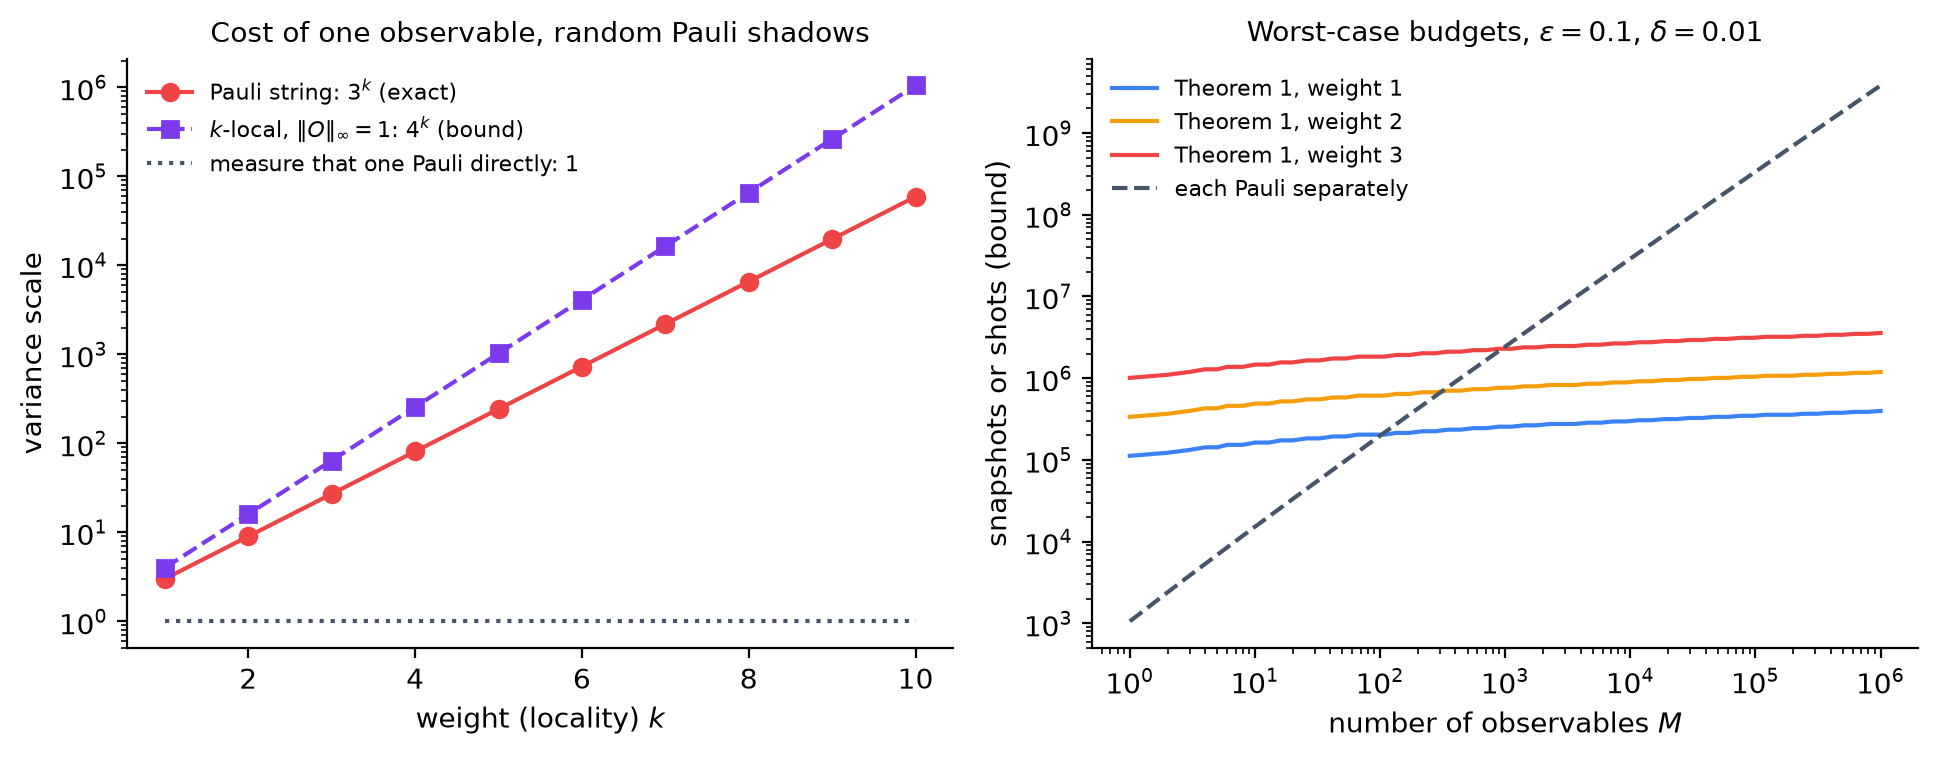

In [2]:
_show_mpl(_lessonfigs.shadow_budget())

*Left: the single-snapshot variance scale for random Pauli shadows, exact $3^k$ for a Pauli string and the $4^k$ bound for a general $k$-local observable with $\|O\|_\infty = 1$, against 1 for measuring that one Pauli directly. Right: the worst-case snapshot budgets $NK$ of [](#thm-l7-07-hkp) for all-weight-$k$ families, against measuring each Pauli separately with Hoeffding's bound and a union bound, at $\epsilon = 0.1$, $\delta = 0.01$. Both curves are upper bounds with conservative constants.*

The right panel is the logarithm in action: shadow budgets barely move as $M$ grows by six orders of magnitude, while separate measurements grow linearly. The crossing points are an artifact of the constants as much as of the physics, and a fair baseline would also group commuting Paulis into shared measurement settings, which the separate count ignores. The lab for this lesson found that, at its small scale, median of means had slightly worse worst-case error than the plain mean; the median buys a provable failure probability from a variance bound alone, not a smaller typical error.

## Which observables are cheap

The ensemble decides the norm. For random $n$-qubit Clifford unitaries the inverse channel is $\mathcal{M}^{-1}(X) = (2^n + 1)X - \operatorname{Tr}(X)\, I$, the snapshot is $(2^n + 1)U^\dagger|b\rangle\langle b|U - I$, and $\|O - \tfrac{\operatorname{Tr} O}{2^n} I\|_{\mathrm{shadow}}^2 \le 3\operatorname{Tr}(O^2)$ [@shadows]. A fidelity observable $O = |\psi\rangle\langle\psi|$ has $\operatorname{Tr}(O^2) = 1$, so Clifford shadows estimate fidelities with any pure target at a cost independent of $n$. Random Pauli measurements instead favor local observables, at $3^k$ or $4^k$ regardless of $n$. A single global Pauli string such as $Z^{\otimes n}$ is the non-example for both: its Pauli shadow cost is $3^n$, and $\operatorname{Tr}(O^2) = 2^n$ makes the Clifford bound exponential too, while measuring that one string directly needs only order $1/\epsilon^2$ copies [@shadows].

:::{prf:theorem} Matching lower bounds (informal statements of Huang, Kueng and Preskill)
:label: thm-l7-07-lower
Any procedure based on a fixed set of single-copy measurements that predicts $M$ arbitrary linear functions $\operatorname{Tr}(O_i\rho)$ to additive error $\epsilon$ requires at least order $\log(M)\max_i \operatorname{Tr}(O_i^2)/\epsilon^2$ copies. Any procedure based on a fixed set of single-copy local measurements that predicts $M$ arbitrary $k$-local linear functions requires at least order $\log(M)\,3^k/\epsilon^2$ copies [@shadows]. These are statements about worst cases over arbitrary families; they do not say that a particular structured family cannot be measured more cheaply.
:::


In [3]:
_show(_lessonfigs.shadow_error_explorer())

**Explore.** Seeded random-Pauli shadows of $\cos(\pi/6)|000\rangle + \sin(\pi/6)|111\rangle$. Left: RMSE of the plain mean over 400 repetitions against the number of snapshots, with the exact prediction $\sqrt{(3^k - \langle P\rangle^2)/N}$ dotted. Right: move the slider to see the 400 estimates of $\langle Z_1\rangle$ (blue) and $\langle X_1X_2X_3\rangle$ (red) concentrate.

:::{dropdown} What the figure shows
The first panel is a log-log plot of root-mean-square error against $N$ from 10 to 4000 for three Pauli observables of the three-qubit state $\cos(\pi/6)|000\rangle + \sin(\pi/6)|111\rangle$: $Z_1$ (weight 1, true value 0.5, variance 2.75), $Z_1Z_2$ (weight 2, true value 1, variance 8) and $X_1X_2X_3$ (weight 3, true value $\sqrt3/2 \approx 0.866$, variance 26.25). Each set of simulated points lies on a straight line of slope $-1/2$ that matches the dotted theory line; the weight-3 line sits a factor of about 3.09 above the weight-1 line. The second panel shows histograms of the error of the 400 estimates at the chosen $N$ (10, 30, 100, 300, 1000 or 4000) for $Z_1$ and $X_1X_2X_3$. At $N = 10$ the weight-3 estimates take only a few widely spaced values; as $N$ grows both histograms narrow around zero, the weight-3 one about three times wider, until at $N = 4000$ both are concentrated within a few bins of width 0.2 around zero.
:::

:::{figure} ../../_static/animations/l7_07_error_vs_snapshots.mp4
:alt: A log-log plot on which three straight lines of slope minus one half are drawn from left to right while simulated points appear on them; an arrow marks the vertical gap between the lowest and highest line.
:width: 100%

The same data set estimates all three observables; the error of each falls like $1/\sqrt N$, offset by the square root of its variance.
:::

:::{dropdown} What the animation shows
Axes show RMSE from 0.01 to about 3 against snapshots $N$ from 10 to 4000, both on log scales. As a sweep moves right, three theory lines of slope $-1/2$ are drawn and simulated RMSE values from 400 seeded repetitions appear on them: blue for $Z_1$, amber for $Z_1Z_2$, red for $X_1X_2X_3$. The variances are listed: $3 - 0.25 = 2.75$, $9 - 1 = 8$, and $27 - 0.75 = 26.25$. An arrow marks the vertical gap between the blue and red lines, $\times\sqrt{26.25/2.75} \approx 3.09$, which means about 9.5 times as many snapshots for the same error. The last lines read: slope $-\tfrac12$, so $N \approx \operatorname{Var}/\epsilon^2$.
:::

:::{important} Reading a shadow claim
Ask five questions. Which ensemble, and is it what the hardware implemented? Which observables, and what are their weights or Hilbert-Schmidt norms? Is the reported error a typical (RMSE) error or a worst case over all $M$ observables at confidence $1 - \delta$? Were the measurements noisy, and if so was the actual channel calibrated and inverted (inverting the ideal $\mathcal{M}$ when the real one differs gives a biased estimator)? Is the comparison against a strong baseline, such as direct measurement of grouped commuting observables? A claim that answers these is checkable; one that quotes only $\log M$ is not.
:::

## Shadows inside a quantum causal workflow

Causal questions about quantum systems are usually questions about processes, not single states. Quantum causal discovery in the sense of Giarmatzi and Costa takes a process matrix as its input and returns causal order, whether the process is Markovian, and, in the Markovian case, the causal mechanisms [@giarmatzi]. Light-touch schemes build a space-time pseudo-density matrix from coarse-grained measurements on a system observed at two times and use it to discriminate between candidate causal structures [@hypothesis]. Either way the data enter as expectation values of chosen observables, and the cost of estimating them is the subject of this lesson. A shadow does not supply identification: it estimates expectation values, and whether a causal target is a function of those values is the identification question of [L7-05](#lesson-l7-05).

```{mermaid}
graph LR
  Q[Causal question] --> T[Identified target]
  T --> O[Observables needed]
  O --> E{Ensemble}
  E -->|local terms| P[Random Pauli]
  E -->|fidelities| C[Random Clifford]
  P --> S[Snapshots]
  C --> S
  S --> MM[Median of means]
  MM --> R[Estimates with error and confidence]
```

*Where a classical shadow sits in a study: the target and the observables come first, the ensemble is chosen to make their shadow norms small, and the report carries the error and confidence of Theorem 1.*

:::{prf:example} Telling identity from dephasing with a Choi-state shadow
:label: ex-l7-07-choi
Send half of $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt2$ through an unknown one-qubit channel $\mathcal{E}$ and shadow the two-qubit output $J = (\mathrm{id}\otimes\mathcal{E})(|\Phi^+\rangle\langle\Phi^+|)$, which is the normalized Choi state with the channel on the second factor. For the identity channel $\langle X\otimes X\rangle_J = 1$; for the complete dephasing channel $\rho \mapsto \tfrac12(\rho + Z\rho Z)$ it is 0, while $\langle Z\otimes Z\rangle_J = 1$ for both. So $Z\otimes Z$ data alone cannot tell the two apart, and the decisive observable $X\otimes X$ has weight 2: its single-snapshot variance is $9 - \langle X\otimes X\rangle^2$, between 8 and 9. A standard error of 0.1 needs at most $9/0.01 = 900$ snapshots, and the same snapshots also give every other two-qubit Pauli expectation of $J$. The same pair of channels is the benchmark example of [L7-08](#lesson-l7-08).
:::

## Compute it

Numpy only, seeded, under five seconds. Part 1 checks the single-qubit channel and its inverse exactly. Part 2 simulates 6000 random-Pauli snapshots of $\cos(\pi/6)|000\rangle + \sin(\pi/6)|111\rangle$, builds full tensor-product snapshots, and estimates four Pauli strings with the mean and with median of means. Part 3 verifies $\mathbb{E}[\hat o_P^2] = 3^k$ for all 63 Pauli strings by exact enumeration. Part 4 computes Theorem 1 budgets and the binomial tail, and part 5 checks the Bell-fidelity variance used in an exercise.


In [4]:
import itertools
import math
import numpy as np

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.diag([1.0 + 0j, -1.0])
H = np.array([[1, 1], [1, -1]], dtype=complex) / math.sqrt(2)
ROT = (H, H @ np.diag([1, -1j]), I2)        # U for the X, Y, Z basis: U maps that eigenbasis to |0>, |1>
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}


def kron(*ops):
    out = np.ones((1, 1), dtype=complex)
    for o in ops:
        out = np.kron(out, o)
    return out


# 1. One qubit: the measurement channel M and its inverse, checked exactly
def channel(rho):
    """M(rho) = E_U sum_b <b|U rho U^dag|b> U^dag|b><b|U with U uniform over the three bases."""
    out = np.zeros((2, 2), dtype=complex)
    for U in ROT:
        for b in range(2):
            v = U.conj().T[:, b]                      # U^dag |b>
            proj = np.outer(v, v.conj())
            out += np.real(v.conj() @ rho @ v) / 3 * proj
    return out


r = np.array([0.4, 0.3, 0.6])
rho1 = (I2 + r[0] * X + r[1] * Y + r[2] * Z) / 2
assert np.allclose(channel(rho1), rho1 / 3 + I2 / 3)          # M(rho) = rho/3 + Tr(rho) I/3
snap_z0 = 3 * np.diag([1, 0]) - I2
print("snapshot for Z basis, outcome 0:", np.real(np.diag(snap_z0)), " eigenvalues", np.linalg.eigvalsh(snap_z0))
kets = [U.conj().T[:, b] for U in ROT for b in range(2)]       # the six eigenstates U^dag|b>
mean_snap = sum(np.real(v.conj() @ rho1 @ v) / 3 * (3 * np.outer(v, v.conj()) - I2) for v in kets)
assert np.allclose(mean_snap, rho1)                            # E[snapshot] = rho exactly
print("E[snapshot] equals rho: True")

# 2. Three qubits: simulate random Pauli measurements of |psi> = cos(pi/6)|000> + sin(pi/6)|111>
n = 3
psi = np.zeros(2 ** n, dtype=complex)
psi[0], psi[-1] = math.cos(math.pi / 6), math.sin(math.pi / 6)
rho = np.outer(psi, psi.conj())
settings = list(itertools.product(range(3), repeat=n))       # 0 = X, 1 = Y, 2 = Z on each qubit
probs = np.array([np.abs(kron(*[ROT[s] for s in st]) @ psi) ** 2 for st in settings])
rng = np.random.default_rng(2024)
N = 6000
s_idx = rng.integers(3 ** n, size=N)
o_idx = np.array([rng.choice(2 ** n, p=probs[s] / probs[s].sum()) for s in s_idx])
bases = np.array(settings)[s_idx]                              # (N, n) basis codes
bits = (o_idx[:, None] >> np.arange(n - 1, -1, -1)) & 1        # qubit 0 is the leftmost factor


def estimate_values(word):
    """Single-snapshot values prod_{j in support} 3 b_j [basis_j = P_j] for a Pauli word like 'ZZI'."""
    val = np.ones(N)
    for j, c in enumerate(word):
        if c != "I":
            val *= 3 * (1 - 2 * bits[:, j]) * (bases[:, j] == "XYZ".index(c))
    return val


# the full snapshot (a tensor product of 3 U^dag|b><b|U - I) for the first 1500 shots
avg = np.zeros((8, 8), dtype=complex)
for t in range(1500):
    factors = []
    for j in range(n):
        v = ROT[bases[t, j]].conj().T[:, bits[t, j]]
        factors.append(3 * np.outer(v, v.conj()) - I2)
    avg += kron(*factors) / 1500
one = kron(*factors)
print(f"one 3-qubit snapshot: trace {np.real(np.trace(one)):.1f}, smallest eigenvalue {np.linalg.eigvalsh(one).min():.1f}")
print(f"average of 1500 snapshots: distance to rho (Frobenius) {np.linalg.norm(avg - rho):.3f}")

for word in ("ZII", "ZZI", "XXX", "YYY"):
    k = sum(c != "I" for c in word)
    truth = float(np.real(np.trace(rho @ kron(*[PAULI[c] for c in word]))))
    v = estimate_values(word)
    se = math.sqrt((3 ** k - truth ** 2) / N)
    mom = np.median(v.reshape(20, N // 20).mean(axis=1))      # median of 20 group means
    print(f"<{word}> true {truth:+.3f}  mean {v.mean():+.3f}  median-of-means {mom:+.3f}  "
          f"predicted std error {se:.3f}  (weight {k}, 3^k = {3 ** k})")
    assert abs(v.mean() - truth) < 4 * se

# 3. E[o^2] = 3^k for every Pauli string and every state: exact sums over all settings and outcomes
signs = 1 - 2 * np.array(list(itertools.product([0, 1], repeat=n)))
for word in itertools.product("IXYZ", repeat=n):
    k = sum(c != "I" for c in word)
    if k == 0:
        continue
    match = np.array([all(c == "I" or st[j] == "XYZ".index(c) for j, c in enumerate(word)) for st in settings])
    val = np.array([[np.prod([3 * signs[o, j] for j, c in enumerate(word) if c != "I"]) for o in range(8)]
                    for _ in settings]) * match[:, None]
    p = probs / 3 ** n
    assert abs(np.sum(p * val) - np.real(np.trace(rho @ kron(*[PAULI[c] for c in word])))) < 1e-12
    assert abs(np.sum(p * val ** 2) - 3 ** k) < 1e-9
print("exact: unbiased and E[o^2] = 3^k for all 63 Pauli strings on 3 qubits")


# 4. The Huang-Kueng-Preskill budget (Theorem 1 constants) and the simple median-of-means lemma
def hkp_budget(shadow_norm_sq, M, eps, delta):
    K = math.ceil(2 * math.log(2 * M / delta))
    Ngroup = math.ceil(34 * shadow_norm_sq / eps ** 2)
    return K, Ngroup, K * Ngroup


M20 = 3 * 20 + 9 * math.comb(20, 2)                            # Pauli strings of weight 1 or 2 on 20 qubits
print("20 qubits, weight <= 2: M =", M20, " (K, N, NK) =", hkp_budget(9, M20, 0.1, 0.01))
print("50 qubits, weight 3: M =", 27 * math.comb(50, 3), " (K, N, NK) =",
      hkp_budget(27, 27 * math.comb(50, 3), 0.05, 0.05))
tail9 = sum(math.comb(9, j) * 0.25 ** j * 0.75 ** (9 - j) for j in range(5, 10))
print(f"K = 9 groups: P(at least 5 of 9 fail) = {tail9:.3f} <= exp(-9/8) = {math.exp(-9 / 8):.3f}")

# 5. Bell-state fidelity under Pauli shadows: O = (II + XX - YY + ZZ)/4, state |Phi+>
phi = np.array([1, 0, 0, 1]) / math.sqrt(2)
O = np.outer(phi, phi.conj())
second, first = 0.0, 0.0
for st in itertools.product(range(3), repeat=2):
    Ub = kron(ROT[st[0]], ROT[st[1]])
    for o in range(4):
        b0, b1 = o >> 1, o & 1
        v = [ROT[st[j]].conj().T[:, (b0, b1)[j]] for j in range(2)]
        snap = kron(*[3 * np.outer(x, x.conj()) - I2 for x in v])
        val = np.real(np.trace(O @ snap))
        p = np.abs(Ub @ phi)[o] ** 2 / 9
        first += p * val
        second += p * val ** 2
print(f"Bell fidelity estimator: mean {first:.3f}, single-snapshot variance {second - first ** 2:.3f}")
assert abs(first - 1) < 1e-12 and abs(second - first ** 2 - 9 / 8) < 1e-12

snapshot for Z basis, outcome 0: [ 2. -1.]  eigenvalues [-1.  2.]
E[snapshot] equals rho: True
one 3-qubit snapshot: trace 1.0, smallest eigenvalue -4.0
average of 1500 snapshots: distance to rho (Frobenius) 0.301
<ZII> true +0.500  mean +0.483  median-of-means +0.460  predicted std error 0.021  (weight 1, 3^k = 3)
<ZZI> true +1.000  mean +1.075  median-of-means +1.035  predicted std error 0.037  (weight 2, 3^k = 9)
<XXX> true +0.866  mean +0.900  median-of-means +0.945  predicted std error 0.066  (weight 3, 3^k = 27)
<YYY> true +0.000  mean +0.045  median-of-means +0.000  predicted std error 0.067  (weight 3, 3^k = 27)
exact: unbiased and E[o^2] = 3^k for all 63 Pauli strings on 3 qubits
20 qubits, weight <= 2: M = 1770  (K, N, NK) = (26, 30600, 795600)
50 qubits, weight 3: M = 529200  (K, N, NK) = (34, 367200, 12484800)
K = 9 groups: P(at least 5 of 9 fail) = 0.049 <= exp(-9/8) = 0.325
Bell fidelity estimator: mean 1.000, single-snapshot variance 1.125


:::{prf:remark} What the output shows
:label: rem-l7-07-output
One three-qubit snapshot has trace 1 and smallest eigenvalue $2\cdot 2\cdot(-1) = -4$, yet the average of 1500 of them is within Frobenius distance about 0.30 of $\rho$, a distance that shrinks like $1/\sqrt N$. The printed standard errors grow by about $\sqrt3$ per unit of weight, as [](#prop-l7-07-variance) predicts, and the Theorem 1 budget for all 1770 weight-$\le 2$ Pauli strings on 20 qubits is $K = 26$ groups of $N = 30600$, that is $NK = 795600$ snapshots.
:::

## Worked example

:::{admonition} Budgeting a shadow experiment
:class: tip

On 20 qubits you want every Pauli expectation value of weight 1 or 2 to within $\epsilon = 0.1$, all simultaneously with probability at least $0.99$. Use [](#thm-l7-07-hkp) with random Pauli measurements and compare with measuring each Pauli separately.

1. Count the observables: $M = 3\cdot 20 + 9\cdot\binom{20}{2} = 60 + 1710 = 1770$.
2. Norm: every observable is a traceless Pauli string of weight at most 2, so by [](#prop-l7-07-variance) the squared shadow norm is at most $3^2 = 9$.
3. Groups: $K = 2\ln(2M/\delta) = 2\ln(354000) \approx 25.55$, rounded up to $K = 26$.
4. Group size: $N = 34\cdot 9/0.1^2 = 30600$. Total $NK = 795600$ snapshots.
5. Baseline: measuring each Pauli in its own basis, Hoeffding's bound with a union bound needs $(2/\epsilon^2)\ln(2M/\delta) \approx 2555.5$, so 2556 shots per observable ([L7-06](#lesson-l7-06); [@hoeffding1963]), and $1770 \cdot 2556 = 4524120$ shots in all.

**Result.** $K = 26$, $N = 30600$, $NK = 795600$ snapshots, about 5.7 times fewer than the separate-measurement bound. Both numbers are conservative upper bounds; the simulation in this lesson shows errors near the $\sqrt{\operatorname{Var}/N}$ prediction, far below what the worst-case constants require.
:::

## Exercises

**1. (Core)** A qubit is measured in the $Y$ basis with outcome eigenvalue $b = -1$. Write the snapshot as a $2\times 2$ matrix, and give its trace, eigenvalues and Bloch vector.

:::{dropdown} Solution
The eigenstate is $|{-}i\rangle = (|0\rangle - i|1\rangle)/\sqrt2$ with projector $\tfrac12(I - Y)$. The snapshot is $3\cdot\tfrac12(I - Y) - I = \tfrac12(I - 3Y) = \begin{pmatrix} 1/2 & 3i/2 \\ -3i/2 & 1/2\end{pmatrix}$. Its trace is 1, its eigenvalues are $\tfrac12(1 \pm 3) = 2, -1$, and its Bloch vector is $(0, -3, 0)$.
:::

**2. (Core)** For the state $\cos(\pi/6)|000\rangle + \sin(\pi/6)|111\rangle$, how many random-Pauli snapshots give a standard error of 0.05 for $\langle Z_1Z_2\rangle$, and for $\langle X_1X_2X_3\rangle$?

:::{dropdown} Solution
$\langle Z_1Z_2\rangle = 1$ (weight 2) gives variance $9 - 1 = 8$, so $N = 8/0.05^2 = 3200$. $\langle X_1X_2X_3\rangle = \sin(\pi/3) = \sqrt3/2$ (weight 3) gives variance $27 - 0.75 = 26.25$, so $N = 26.25/0.0025 = 10500$. The same 10500 snapshots serve both.
:::

**3. (Stretch)** On 50 qubits, use [](#thm-l7-07-hkp) to budget all Pauli strings of weight exactly 3 with $\epsilon = 0.05$ and $\delta = 0.05$.

:::{dropdown} Solution
$M = 27\binom{50}{3} = 27\cdot 19600 = 529200$. $K = \lceil 2\ln(2\cdot 529200/0.05)\rceil = \lceil 2\ln(21168000)\rceil = \lceil 33.74\rceil = 34$. $N = \lceil 34\cdot 27/0.0025\rceil = 367200$. Total $NK = 12484800$ snapshots, independent of the 50 qubits except through $M$ inside the logarithm.
:::

**4. (Stretch)** Show that for one qubit the uniform random Clifford ensemble gives the same measurement channel as random Pauli measurements, and check the formula $\mathcal{M}^{-1}(X) = (2^n + 1)X - \operatorname{Tr}(X) I$ at $n = 1$.

:::{dropdown} Solution
The single-qubit Clifford group (modulo phases) maps $|0\rangle$ and $|1\rangle$ to the six eigenstates of $X$, $Y$, $Z$, and a uniformly random element sends the computational basis to each of the three Pauli eigenbases with probability $1/3$ (the 24 elements split evenly). So the average $\mathbb{E}\sum_b \langle b|U\rho U^\dagger|b\rangle U^\dagger|b\rangle\langle b|U$ is the same as for random Pauli bases, $\tfrac13\rho + \tfrac13\operatorname{Tr}(\rho) I$. At $n = 1$, $(2^n + 1)X - \operatorname{Tr}(X) I = 3X - \operatorname{Tr}(X) I$, matching [](#prop-l7-07-onequbit).
:::

**5. (Challenge)** Estimate the fidelity with the Bell state $|\Phi^+\rangle$ from two-qubit random Pauli shadows, using $O = |\Phi^+\rangle\langle\Phi^+| = \tfrac14(II + XX - YY + ZZ)$. Compute the single-snapshot variance when the state is $|\Phi^+\rangle$ itself, and compare with the Clifford bound $3\operatorname{Tr}(O^2)$.

:::{dropdown} Solution
By [](#eq-l7-07-estimator), $\operatorname{Tr}(O\hat\rho) = \tfrac14(1 + \hat o_{XX} - \hat o_{YY} + \hat o_{ZZ})$, and at most one of the three Pauli terms is non-zero in a given snapshot (both qubits must share that basis). With probability $6/9$ the bases differ and the value is $\tfrac14$. With probability $1/9$ each, both are $P$ and the value is $\tfrac14(1 + 9 s_P b_1b_2)$, where $s_X = s_Z = 1$, $s_Y = -1$. For $|\Phi^+\rangle$, $s_P b_1 b_2 = +1$ always ($\langle XX\rangle = \langle ZZ\rangle = 1$, $\langle YY\rangle = -1$), so the value is $10/4$. Mean: $\tfrac69\cdot\tfrac14 + \tfrac39\cdot\tfrac{10}{4} = 1$. Second moment: $\tfrac69\cdot\tfrac1{16} + \tfrac39\cdot\tfrac{100}{16} = \tfrac{306}{144} = 2.125$. Variance $2.125 - 1 = 9/8 = 1.125$, which the code verifies. The Clifford bound is $3\operatorname{Tr}(O^2) = 3$; for two qubits Pauli shadows are competitive. For the $n$-qubit GHZ fidelity they are not: in the setting where every qubit is measured in $Z$ (probability $3^{-n}$), the GHZ state gives all-equal outcomes, the snapshot is diagonal with entries $2$ or $-1$ per qubit, and the estimator equals $\tfrac12\big(2^n + (-1)^n\big)$. So $\mathbb{E}[\hat o^2] \ge 3^{-n}\cdot\tfrac14\big(2^n + (-1)^n\big)^2 \approx \tfrac14(4/3)^n$, which grows exponentially (at $n = 2$ this is the value $10/4$ above), while the Clifford bound stays 3.
:::

**6. (Challenge)** Using [](#lem-l7-07-mom), how many groups $K$ and what total $NK$ (in units of $\sigma^2/\epsilon^2$) guarantee all of $M = 1000$ estimates to within $\epsilon$ with probability $0.99$? Compare with the constants of [](#thm-l7-07-hkp). What does the comparison say about reading constants?

:::{dropdown} Solution
Union bound: each estimate may fail with probability $\delta/M = 10^{-5}$, so $K \ge 8\ln(10^5) \approx 92.1$, giving $K = 93$, and $N = 4\sigma^2/\epsilon^2$, so $NK = 372\,\sigma^2/\epsilon^2$. Theorem 1 gives $K = \lceil 2\ln(2\cdot 10^5)\rceil = \lceil 24.4\rceil = 25$ and $N = 34\sigma^2/\epsilon^2$, so $NK = 850\,\sigma^2/\epsilon^2$. Both are valid upper bounds from different proofs; neither is the true requirement. Constants in worst-case bounds compare proofs, not methods, so comparisons between methods should use the same style of bound or, better, simulation and experiment under stated conditions.
:::

## Check your understanding

**1. A qubit measured in the $Z$ basis gives outcome 0. What are the eigenvalues of its random-Pauli snapshot?**

- **A.** $\tfrac23$ and $\tfrac13$
- **B.** $2$ and $-1$
- **C.** $3$ and $0$
- **D.** $1$ and $0$

:::{dropdown} Show the answer
**B. $2$ and $-1$**

The snapshot is $3|0\rangle\langle 0| - I = \operatorname{diag}(2,-1)$. It has unit trace but a negative eigenvalue; it is an unbiased estimator, not a state.
:::

**2. With random Pauli shadows on 100 qubits, which expectation value is cheapest to estimate to a fixed error?**

- **A.** The fidelity with a 100-qubit GHZ state
- **B.** $\langle Z^{\otimes 100}\rangle$
- **C.** All three cost the same, because cost grows only like $\log M$
- **D.** $\langle Z_1 Z_2\rangle$

:::{dropdown} Show the answer
**D. $\langle Z_1 Z_2\rangle$**

The single-snapshot variance of a weight-$k$ Pauli string is $3^k - \langle P\rangle^2$: at most 9 for $Z_1Z_2$ but about $3^{100}$ for the global string. The GHZ fidelity estimator has second moment at least about $\tfrac14(4/3)^n$, so its variance also grows exponentially (see the challenge exercise). The $\log M$ factor concerns the number of observables, not their structure.
:::

**3. In the Huang-Kueng-Preskill theorem, how does the total number of snapshots depend on the number $M$ of observables?**

- **A.** Not at all
- **B.** Through $K = 2\ln(2M/\delta)$, so logarithmically
- **C.** Through $\sqrt M$
- **D.** Linearly, $M$ times the cost of one observable

:::{dropdown} Show the answer
**B. Through $K = 2\ln(2M/\delta)$, so logarithmically**

$NK$ snapshots suffice with $K = 2\ln(2M/\delta)$ groups of $N = (34/\epsilon^2)\max_i\|O_i - \operatorname{Tr}(O_i) I/2^n\|_{\mathrm{shadow}}^2$; $M$ enters only through the logarithm, while the maximal shadow norm can still be large.
:::

**4. For independent outcomes in $[-1, 1]$, Hoeffding's inequality $\Pr(|\bar x - \mu| \ge \epsilon) \le 2e^{-N\epsilon^2/2}$ is used to guarantee error $\epsilon = 0.1$ with failure probability $\delta = 0.05$. Which number of shots suffices?** *(Review of [L7-06](#lesson-l7-06))*

- **A.** 200
- **B.** 74
- **C.** 7378
- **D.** 738

:::{dropdown} Show the answer
**D. 738**

Solve $2e^{-N\epsilon^2/2} \le \delta$: $N \ge (2/\epsilon^2)\ln(2/\delta) = 200\ln 40 \approx 737.8$, so 738 shots.
:::

## Common misconceptions

- **\"A classical shadow is a cheap full description of the state.\"** It is a data set from which linear functions with small shadow norm can be predicted. Reconstructing the whole state to fixed accuracy still needs exponentially many measurements; the guarantee is per observable family, set by the largest shadow norm in it.
- **\"The $\log M$ scaling means any observable can be estimated with a system-size-independent number of measurements.\"** The bound also contains $\max_i\|O_i\|_{\mathrm{shadow}}^2$, which for random Pauli measurements is $3^k$ for a weight-$k$ string and for random Clifford measurements is bounded by $3\operatorname{Tr}(O^2)$. A global Pauli string is exponentially expensive under both.
- **\"Each snapshot should be a valid density matrix, so project it before averaging.\"** Projecting single snapshots destroys unbiasedness: for one qubit the projected records average to $\mathcal{M}(\rho)$, with the Bloch vector shrunk by 3. Average first, then project the final estimate if a physical state is needed.
- **\"Median of means makes the estimate more accurate than the mean.\"** It gives a guaranteed failure probability $\delta$ with only a variance assumption, at the price of $K \propto \ln(1/\delta)$ groups. In typical simulations with bounded estimators the plain mean can have equal or smaller error.

:::{caution} Scope and limits
Everything here assumes ideal, independent random Pauli (or Clifford) measurements with the stated uniform distribution; noisy readout or gates change $\mathcal{M}$, and inverting the ideal channel then biases the estimator unless the real channel is characterized. The simulations are classical computations on 1 to 4 qubits with seeded randomness; they check formulas, not hardware. Theorem 1's constants are conservative and its lower bounds are quoted as the source's informal statements, which assume single-copy, fixed (non-adaptive) measurements. Random Clifford shadows were stated, not simulated. Classical shadows estimate state properties; using them for a causal target presupposes that the target has been identified from the measured quantities.
:::

:::{seealso} Where this leads
[L7-08](#lesson-l7-08) treats estimation error and snapshot budgets as quantities a benchmark must report, and reuses the identity-versus-dephasing pair of the Choi-state example. [L7-09](#lesson-l7-09) asks for a protocol with stated error and confidence targets, for which Theorem 1 and the median-of-means lemma give templates. [L7-10](#lesson-l7-10) returns to the open question of which causal targets of quantum processes can be expressed through low-weight observables.
:::

:::{dropdown} For instructors

**Why this lesson.** Classical shadows are the most widely cited example of a learning guarantee in quantum information, and the most misread. Deriving the estimator and its exact Pauli cost lets students see precisely which part of the claim is free ($\ln M$, system size) and which is not (the shadow norm) [@shadows; @nielsenchuang].

**Teaching notes.**

- Start with the six-point picture: a single-qubit snapshot at Bloch radius 3 is the fastest way to dislodge the idea that snapshots are states. Ask students to predict the average of the six points weighted by Born probabilities before showing that it is $\vec r$.
- Have students derive $\mathbb{E}[\hat o_P^2] = 3^k$ from the basis-matching argument before showing the shadow-norm definition; the definition then reads as a worst case of a computation they already did.
- Spend time on the constants: compute Theorem 1 budgets and the self-contained median-of-means budget for the same problem and discuss why they differ. This is the critical-reading skill of the level.
- Use the interactive figure's histograms at $N = 10$: the weight-3 estimator takes only a few values, which explains why single runs of high-weight estimators look erratic.

**Assessment.** The budget exercises test whether students can apply Theorem 1 correctly (natural logarithm, traceless part, rounding). The Bell-fidelity challenge tests the estimator at the level of individual snapshots, and the median-of-means challenge tests whether they can distinguish a property of a proof from a property of a method.

**Going further.** Derive the Clifford inverse channel $\mathcal{M}^{-1}(X) = (2^n + 1)X - \operatorname{Tr}(X) I$ from the unitary 2-design property, and read Supplementary Section 5 of Huang, Kueng and Preskill for the Clifford and Pauli shadow-norm bounds and Sections 7 and 8 for the lower bounds [@shadows]. Preskill's lecture notes provide background on quantum channels and measurement [@preskill].

:::

## References

This lesson draws on [@shadows; @nielsenchuang; @preskill; @giarmatzi; @hypothesis; @watrous; @hoeffding1963].

**Further reading.**

- [@shadows]: Main text Theorem 1 and Supplementary Section 1: definitions (S1) to (S7), Lemma 1, Theorem 1 with constants (S13), the Clifford and Pauli examples (S16) and (S17), and the informal lower bounds.
- [@watrous]: Chapter 2 for channels, Choi representations and the linear-algebra conventions used in the inverse-channel argument.
- [@giarmatzi]: A causal discovery algorithm whose input is a process matrix; a natural place to ask which of its inputs can be estimated through low-weight observables.

**Next:** [L7-08 · Reproducible quantum causal benchmarks](#lesson-l7-08)
